#### Пункт 1

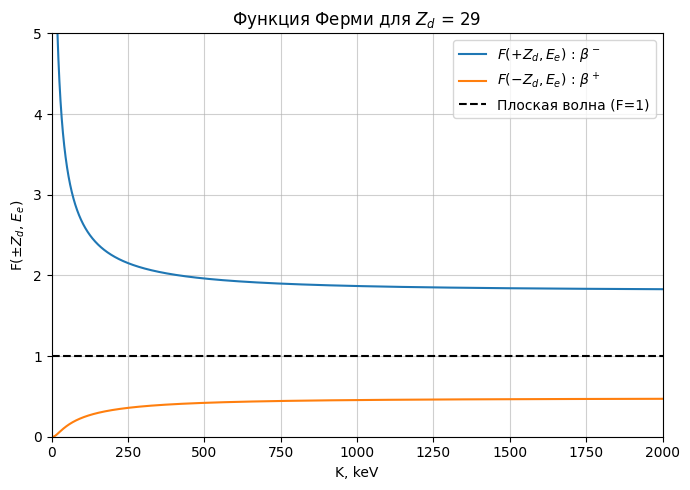

In [1]:
import numpy as np
import matplotlib.pyplot as plt

m_e = 511e3       
E_0 = 2e6       
Z_d = 29
alpha = 1/137

def F(Z, K):
    K = np.asarray(K)
    E = K + m_e
    p = np.sqrt(E**2 - m_e**2)
    eta = Z * alpha * E / p
    return (2*np.pi * eta) / (1 - np.exp(-2*np.pi*eta))

K = np.linspace(100, E_0, 50000)  

F_plus = F(+Z_d, K)
F_minus = F(-Z_d, K)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(K/1e3, F_plus, label=r'$F(+Z_d, E_e)$ : $\beta^-$')
ax.plot(K/1e3, F_minus, label=r'$F(-Z_d, E_e)$ : $\beta^+$')
ax.axhline(1, color='black', ls='--', label='Плоская волна (F=1)')
ax.set_xlabel('K, keV')
ax.set_ylabel(r'F($\pm Z_d$, $E_e$)')
ax.set_title(r'Функция Ферми для $Z_d$ = 29')
ax.legend()
ax.grid(alpha=0.6)
ax.set_xlim(0, 2000)
ax.set_ylim(0, 5)
# ax.set_xscale("log")
plt.tight_layout()
plt.show()


#### Пункт 2

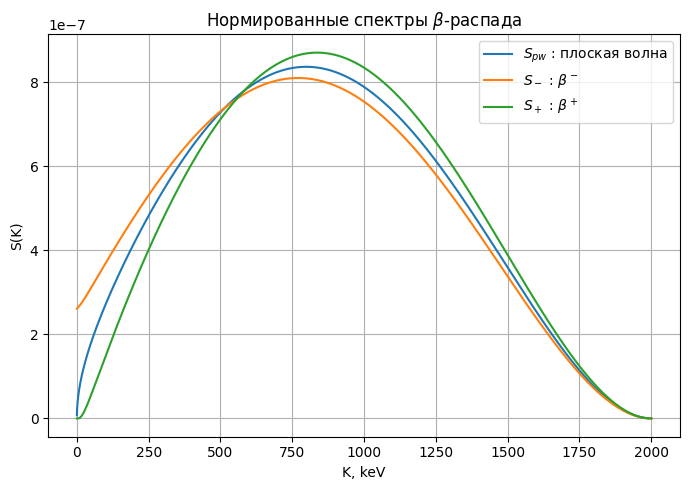

In [2]:
def spectrum(K, Z):
    E_e = K + m_e
    p_e = np.sqrt(E_e**2 - m_e**2)
    
    if Z != 0:
        F_val = F(Z, K)
    else:
        F_val = 1.0
    
    return F_val * p_e * E_e * (E_0 - K)**2

Zs = (0, Z_d, -Z_d)
labels = (r'$S_{pw}$ : плоская волна', r'$S_-$ : $\beta^-$' , r'$S_+$ : $\beta^+$')

fig, ax = plt.subplots(figsize=(7, 5))

for z, label in zip(Zs, labels):
    S = spectrum(K, z)
    norm = np.trapezoid(S, K)
    S_norm = S / norm
    ax.plot(K/1e3, S_norm, label=label)

ax.set_xlabel('K, keV')
ax.set_ylabel('S(K)')
ax.set_title(r'Нормированные спектры $\beta$-распада')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()


####  Параметр Зоммерфельда $\eta \sim 1/\beta$ для малых энегрий велик, поэтому при $\beta^-$ распаде $F \gg 1$ усиливает спектр, а при $\beta^+$ распаде $F \ll 1$ подавляет спектр

#### Пункт 3

/tmp/ipykernel_6828/411303765.py:1: RuntimeWarning: invalid value encountered in divide
  ratio_plus = spectrum(K, -Z_d) / spectrum(K, 0)
/tmp/ipykernel_6828/411303765.py:2: RuntimeWarning: invalid value encountered in divide
  ratio_minus = spectrum(K, Z_d) / spectrum(K, 0)


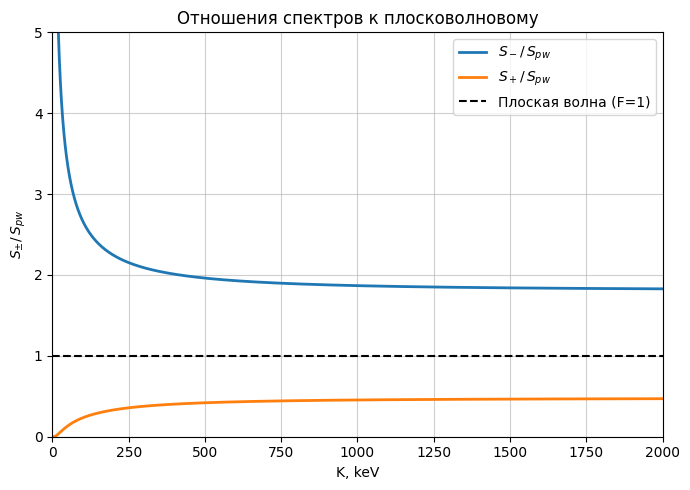

In [3]:
ratio_plus = spectrum(K, -Z_d) / spectrum(K, 0)
ratio_minus = spectrum(K, Z_d) / spectrum(K, 0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(K/1e3, ratio_minus, label=r'$S_-/\,S_{pw}$', lw=2)
ax.plot(K/1e3, ratio_plus, label=r'$S_+/\,S_{pw}$', lw=2)
ax.axhline(1, color='black', ls='--', label='Плоская волна (F=1)')
ax.set_xlabel('K, keV')
ax.set_ylabel(r'$S_{\pm} /\, S_{pw}$')
ax.set_title('Отношения спектров к плосковолновому')
ax.legend()
ax.grid(alpha=0.6)
ax.set_xlim(0, 2000)
ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()


#### Отношения в точности совпадают с функцией Ферми по определению: $$S = F \cdot p_e E_e (E_0 - K)^2$$ $$S_{pw} = 1 \cdot p_e E_e (E_0 - K)^2$$ $$\frac{S}{S_{pw}} = F$$ 

#### Пункт 4

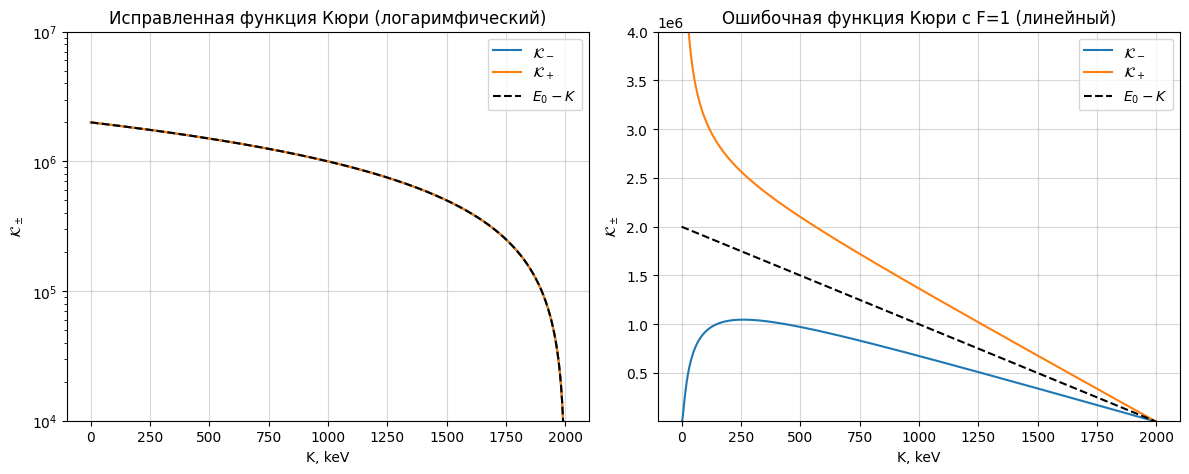

In [4]:
def kurie_correct(K, Z):
    S = spectrum(K, Z)
    p_e = np.sqrt(K**2 + 2*K*m_e)
    E_e = K + m_e
    return np.sqrt(S / F(Z, K) / p_e / E_e)

def kurie_wrong(K, Z):
    S = spectrum(K, Z)
    p_e = np.sqrt(K**2 + 2*K*m_e)
    E_e = K + m_e
    return np.sqrt(S / (1.0 * p_e * E_e))

K_correct_minus = kurie_correct(K=K, Z=-Z_d)
K_correct_plus = kurie_correct(K=K, Z=Z_d)

K_wrong_minus = kurie_wrong(K=K, Z=-Z_d)
K_wrong_plus = kurie_wrong(K=K, Z=Z_d)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(K/1e3, K_correct_minus, label=r'$\mathcal{K}_-$')
axs[0].plot(K/1e3, K_correct_plus, label=r'$\mathcal{K}_+$')
axs[0].plot(K/1e3, E_0 - K, '--', color='black', label=r'$E_0 - K$')
axs[0].set_xlabel('K, keV')
axs[0].set_ylabel(r'$\mathcal{K}_\pm$')
axs[0].set_title('Исправленная функция Кюри (логаримфический)')
axs[0].legend()
axs[0].set_yscale("log")
axs[0].grid(alpha=0.5)
axs[0].set_ylim(1e4, 1e7)

axs[1].plot(K/1e3, K_wrong_minus, label=r'$\mathcal{K}_-$')
axs[1].plot(K/1e3, K_wrong_plus, label=r'$\mathcal{K}_+$')
axs[1].plot(K/1e3, E_0 - K, '--', color='black', label=r'$E_0 - K$')
axs[1].set_xlabel('K, keV')
axs[1].set_ylabel(r'$\mathcal{K}_\pm$')
axs[1].set_title('Ошибочная функция Кюри с F=1 (линейный)')
axs[1].legend()
# axs[1].set_yscale("log")
axs[1].grid(alpha=0.5)
axs[1].set_ylim(1e4, 4e6)

plt.tight_layout()
plt.show()


#### Ошибочная функция Кюри ведёт либо к большему наклону, что даёт $m^2_{\nu} < 0$, либо к меньшему наклону, что даёт $m^2_{\nu} > 0$ 

#### Пункт 5
#### Функция Ферми $F \sim \frac{|\psi|^2}{|\psi_{asympt}|}$ описывает, как Кулоновское поле искажает вероятность, но никак не влияет на кинематику процесса, которая уже вшита в саму волновую функцию $\psi$. Поэтому граница $K_{\max} = E_0 - m_{\nu}$ не может изменяться. 